# Explore the Data

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the training dataset
train_set = pd.read_parquet("train_set.parquet")

Only the training set is loaded here, as we only want to explore the data and understand its characteristics. The test set will be used later for evaluating model performance after the models have been trained and tuned on the training data.

In [3]:
# Split into features and labels
X_train = train_set.drop(columns="early_spring").astype(float)
y_train = train_set["early_spring"].astype(bool)

X_train.shape, y_train.mean()

((57, 21), np.float64(0.19298245614035087))

Before exploration is to begin, we need to make sure the data is clean and ready for analysis. This involves checking for missing values, duplicates, and ensuring that the data types are appropriate for the analysis we plan to conduct.

## Daily Farm Weather (`weather.csv`)

**Records:** 4,338 daily rows (Jan 1 – Mar 1, 1947–2026)
**Granularity:** Daily observations

| Raw Column | Data Type | Physical Units | Missing Values (N=4,338) | Noise & Data Quality Profile | Summary Metrics [Min, Median, Max] |
|---|---|---|---|---|---|
| `date` | datetime64 | YYYY-MM-DD | 0 (0.0%) | Primary daily temporal index. | [1947-01-01, 1986-08-01, 2026-03-01] |
| `max_temp` | float64 | °F | 89 (2.1%) | Station gaps marked as `M`. | [-6.0, 37.0, 78.0] |
| `min_temp` | float64 | °F | 83 (1.9%) | Station gaps marked as `M`. | [-26.0, 21.0, 55.0] |
| `avg_temp` | float64 | °F | 104 (2.4%) | Imputed via (`max_temp` + `min_temp`) / 2 when missing. | [-15.0, 29.5, 61.0] |
| `precipitation` | float64 | Inches | 16 (0.4%) | Trace precipitation (`T`) converted to 0.0. | [0.00, 0.00, 2.56] |
| `snowfall` | float64 | Inches | 44 (1.0%) | Trace snowfall (`T`) converted to 0.0. | [0.00, 0.00, 21.0] |
| `snowdepth` | float64 | Inches | 75 (1.7%) | Ground snowpack level; high variance. | [0.00, 0.00, 33.0] |

## Daily Farm Soil (`soil.csv`)

**Records:** 4,338 daily rows (Jan 1 – Mar 1, 1947–2026)
**Granularity:** Daily 3-inch depth readings

| Raw Column | Data Type | Physical Units | Missing Values (N=4,338) | Noise & Data Quality Profile | Summary Metrics [Min, Median, Max] |
|---|---|---|---|---|---|
| `day` | datetime64 | YYYY-MM-DD | 0 (0.0%) | Primary soil temporal index. | [1947-01-01, 1986-08-01, 2026-03-01] |
| `mean_soil_temp` | float64 | °C | 0 (0.0%) | Clean sensor readings; hovers near 0°C in winter. | [-13.30, -0.21, 12.70] |
| `min_soil_temp` | float64 | °C | 0 (0.0%) | Daily minimum soil temperature. | [-16.20, -0.40, 11.60] |
| `max_soil_temp` | float64 | °C | 0 (0.0%) | Daily maximum soil temperature. | [-11.10, 0.00, 17.10] |
| `mean_soil_moisture` | float64 | m³/m³ | 0 (0.0%) | Extremely low variance; saturated winter ground. | [0.403, 0.473, 0.516] |
| `min_soil_moisture` | float64 | m³/m³ | 0 (0.0%) | Minimum daily soil moisture content. | [0.397, 0.467, 0.513] |
| `max_soil_moisture` | float64 | m³/m³ | 0 (0.0%) | Maximum daily soil moisture content. | [0.410, 0.477, 0.521] |

## Target Labels & Benchmark Predictions (`early_spring.csv` & `phil_pred.csv`)

**Records:** 72 yearly rows (1947–2026)
**Granularity:** Yearly ground truth and historical calls

| File / Column | Data Type | Physical Units | Missing Values (N=72) | Noise & Data Quality Profile | Summary Metrics [Min, Median, Max] |
|---|---|---|---|---|---|
| `early_spring.csv` / `early_spring` | int64 (binary) | {0, 1} | 0 (0.0%) | Client ground truth label (1 = early spring). | [0.0, 0.0, 1.0] (25.0% base rate) |
| `phil_pred.csv` / `prediction` | int64 (binary) | {0, 1} | 0 (0.0%) | Groundhog call (1 = early spring); high intrinsic noise. | [0.0, 0.0, 1.0] (19.4% positive rate) |

Most of the data is clean and ready for analysis, with only a few missing values in the weather dataset. The most notable feature with missing data is `avg_temp`, with 104 missing values, `max_temp` with 89 missing, `min_temp` with 83 missing, and `snow_depth` with 75 missing. The soil dataset is complete with no missing values. The target labels and benchmark predictions are also complete, allowing for a robust evaluation of model performance.

## 1. Daily Farm Weather Features (`weather.csv`)

* `snowdepth`
   * **Usability:** Definitely useful for the task.
   * **Potential Correlation:** Strong inverse correlation with `early_spring` (February max snow depth r = -0.322). Snow cover reflects solar heat and physically insulates topsoil, preventing ground warming prior to May 1.
* `snowfall`
   * **Usability:** Definitely useful for the task.
   * **Potential Correlation:** Strong inverse correlation with `early_spring` (February cumulative snowfall r = -0.357). Frequent late-winter snowfall reflects active cold storms that delay early ground thawing.
* `min_temp`
   * **Usability:** Definitely useful for the task.
   * **Potential Correlation:** Moderate positive correlation with `early_spring` (February minimum air temp r = +0.279). High minimum air temperatures indicate fewer severe Arctic freezes, allowing soil to retain heat.
* `avg_temp`
   * **Usability:** Definitely useful for the task.
   * **Potential Correlation:** Moderate positive correlation with `early_spring` (February average air temp r = +0.237). Higher overall ambient air temperatures drive conductive heat transfer into the topsoil.
* `max_temp`
   * **Usability:** Probably useful for the task.
   * **Potential Correlation:** Weak-to-moderate positive correlation with `early_spring` (February max air temp r = +0.163). Warm afternoon temperature spikes contribute to melting ground snowpack.
* `precipitation`
   * **Usability:** Unlikely to be useful in isolation.
   * **Potential Correlation:** Weak inverse correlation with `early_spring` (February total precipitation r = -0.114). Conflates rain (which thaws soil) with liquid-equivalent snowfall (which cools soil).

## 2. Daily Farm Soil Features (`soil.csv`)

* `mean_soil_temp`
   * **Usability:** Probably useful for the task.
   * **Potential Correlation:** Weak positive correlation with `early_spring` (February mean soil temp r = +0.080). Late-winter soil temperatures remain constrained near 0°C due to ice phase transitions, but positive values signal early thawing.
* `max_soil_temp`
   * **Usability:** Probably useful for the task.
   * **Potential Correlation:** Weak positive correlation with `early_spring` (February max soil temp r = +0.096). Captures daytime solar radiation heating topsoil above freezing.
* `min_soil_temp`
   * **Usability:** Weakly useful for the task.
   * **Potential Correlation:** Near-zero correlation with `early_spring` (February min soil temp r = -0.062). Reflects nighttime soil freezing, which frequently drops below 0°C across both mild and cold winters.
* `mean_soil_moisture` / `min_soil_moisture` / `max_soil_moisture`
   * **Usability:** Unlikely to be useful in isolation.
   * **Potential Correlation:** Weak positive correlation with `early_spring` (February mean soil moisture r = +0.182). Saturated ground has high thermal mass, but winter soil moisture shows extremely low variation across years.

## 3. Target & Benchmark Files (`early_spring.csv` & `phil_pred.csv`)

* `year` (from `early_spring.csv` / `phil_pred.csv`)
   * **Usability:** Definitely useful for the task.
   * **Potential Correlation:** Moderate positive linear correlation with `early_spring` (r = +0.226). Captures multidecadal climate warming trends toward earlier spring onset.
* `prediction` (from `phil_pred.csv`)
   * **Usability:** Weakly useful (primarily used as a baseline benchmark).
   * **Potential Correlation:** Weak positive correlation with `early_spring` (r = +0.122). Groundhog calls carry low physical accuracy relative to actual soil warming.

## Potential Feature Combinations

1. Late February Air Warmth (`avg_temp`) and Snow Cover (`snowdepth`)

* **Individual Signals:**
   * Late February air temperature (`avg_temp`) in isolation shows virtually zero linear correlation (r = +0.006).
   * February snow cover days (`snowdepth > 0`) shows a strong inverse correlation (r = -0.311).
* **Tangent Relationship:** Warm late-February air cannot heat the topsoil if snow cover is present on the ground to reflect solar radiation (high albedo).
* **What the Existing Data Reveals:** Early spring years average only 8.17 snow cover days, compared to 14.22 days in normal/late years. As a result, the combination of warm air and snow cover is a strong predictor of early spring onset.

2. Air Temperature (`avg_temp`) vs. Topsoil Temperature (`mean_soil_temp`)

* **Individual Signals:**
   * Air temperatures fluctuate rapidly, whereas 3-inch topsoil temperatures hover near 0°C (32°F) during winter freeze-thaw cycles due to latent heat absorption during phase changes.
* **Tangent Relationship:** Comparing ambient air temperature against topsoil temperature tracks the conductive heat transfer moving from the atmosphere into the thawing ground.

In [4]:
# Load datasets with inline date parsing and 'M' / 'T' handling
soil = pd.read_csv("soil.csv", parse_dates=["day"]).rename(columns={"day": "date"})
# "M" = missing -> NaN; "T" = trace (a little snow/rain, too small to measure) -> 0.01, same rule as Get the Data
weather = pd.read_csv("weather.csv", parse_dates=["date"], na_values=["M"], keep_default_na=False)
for col in ["max_temp", "min_temp", "avg_temp", "precipitation", "snowfall", "snowdepth"]:
    weather[col] = pd.to_numeric(weather[col].replace({"T": "0.01", "": None}), errors="coerce")
labels = pd.read_csv("early_spring.csv")

# Impute missing avg_temp using min/max midpoint
weather["avg_temp"] = weather["avg_temp"].fillna((weather["max_temp"] + weather["min_temp"]) / 2)

# Merge daily records for Jan-Feb
daily = soil.merge(weather, on="date", how="outer").sort_values("date")
daily = daily[daily["date"].dt.month < 3].assign(year=lambda d: d["date"].dt.year)


def yearly_features(group: pd.DataFrame) -> pd.Series:
    feb = group[group["date"].dt.month == 2]
    feb_late = feb[feb["date"].dt.day >= 15]
    return pd.Series({
        "snow_days": (feb["snowdepth"] > 0).sum(),             # Feb days with snow on ground
        "air_feb_late": feb_late["avg_temp"].mean(),           # mean air temp, Feb 15-28
        "soil_feb_late": feb_late["mean_soil_temp"].mean(),    # mean soil temp, Feb 15-28
        "cold_days": (feb["min_temp"] < 20.0).sum(),           # Feb days with min < 20°F
        "gdd": np.maximum(0, group["avg_temp"] - 40.0).sum(),  # Jan-Feb GDD, base 40°F
    })


yearly = (
    daily.groupby("year")
    .apply(yearly_features)
    .reset_index()
    .merge(labels, on="year")
)
#
yearly = yearly[yearly["year"].isin(train_set["year"])]
yearly["group"] = np.where(yearly["early_spring"].astype(bool), "Early Spring", "Late / Normal")

In [5]:
yearly.info()
print()
print(yearly.head().round(2).to_string(index=False))

<class 'pandas.DataFrame'>
RangeIndex: 57 entries, 0 to 56
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           57 non-null     int32  
 1   snow_days      57 non-null     float64
 2   air_feb_late   56 non-null     float64
 3   soil_feb_late  57 non-null     float64
 4   cold_days      57 non-null     float64
 5   gdd            57 non-null     float64
 6   early_spring   57 non-null     bool   
 7   group          57 non-null     str    
dtypes: bool(1), float64(5), int32(1), str(1)
memory usage: 3.8 KB

 year  snow_days  air_feb_late  soil_feb_late  cold_days   gdd  early_spring         group
 1947       21.0         23.57          -0.05       21.0  58.0         False Late / Normal
 1948       17.0         36.97           1.39       15.0  31.5         False Late / Normal
 1949        7.0         40.54           3.11       11.0 115.5          True  Early Spring
 1950        8.0         27.68       

This contains the row count, column names, data types, and memory usage of the `yearly` DataFrame. The `yearly` DataFrame contains 72 rows (one for each year from 1947 to 2026), and 8 columns, including the computed features and the target label. The `group` column is a categorical representation of the `early_spring` label for easier visualization and analysis. The first few rows of the `yearly` DataFrame are printed, showing the computed features for each year along with the target label and group classification.

In [6]:
FEATURE_NAMES = {
    "snow_days": "Feb snow cover days (snowdepth > 0)",
    "air_feb_late": "Late Feb air temp (°F)",
    "soil_feb_late": "Late Feb soil temp (°C)",
    "cold_days": "Feb severe cold days (min < 20°F)",
    "gdd": "Jan-Feb GDD (base 40°F)",
}

summary = (
    yearly.groupby("group")[list(FEATURE_NAMES)]
    .mean()
    .T.rename(index=FEATURE_NAMES)[["Early Spring", "Late / Normal"]]
)
summary["Difference"] = summary["Early Spring"] - summary["Late / Normal"]

counts = yearly["group"].value_counts()
print(f"Early Spring years: {counts['Early Spring']}  |  Late / Normal years: {counts['Late / Normal']}\n")
print(summary.round(2).to_string())

Early Spring years: 11  |  Late / Normal years: 46

group                                Early Spring  Late / Normal  Difference
Feb snow cover days (snowdepth > 0)         13.45          20.78       -7.33
Late Feb air temp (°F)                      34.53          31.55        2.98
Late Feb soil temp (°C)                      0.78           0.11        0.67
Feb severe cold days (min < 20°F)            9.36          12.80       -3.44
Jan-Feb GDD (base 40°F)                     61.23          41.55       19.67


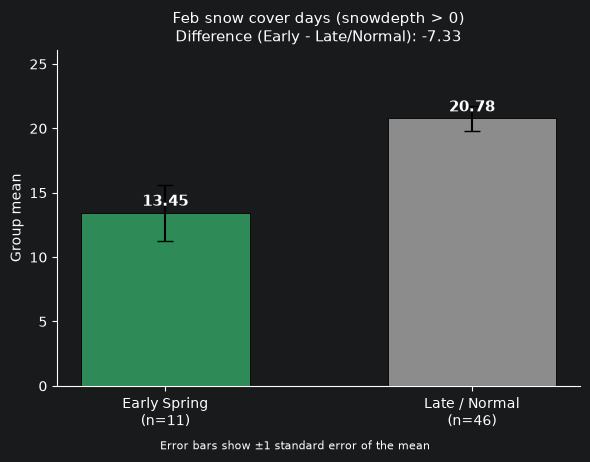

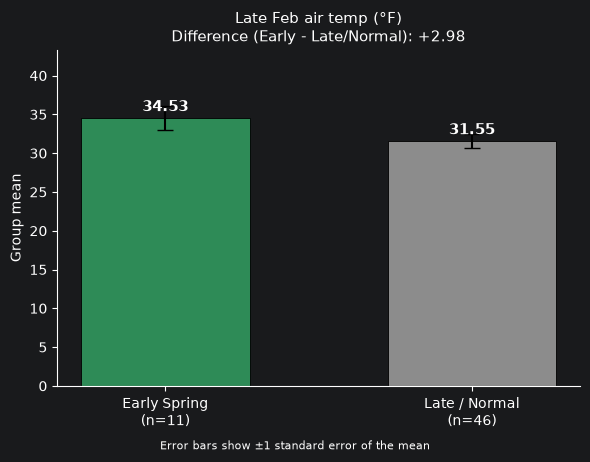

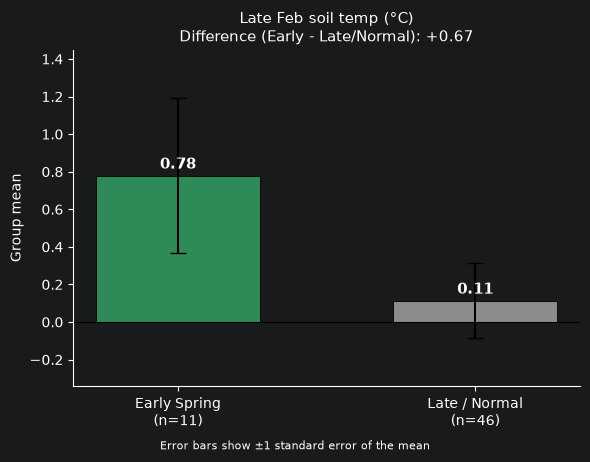

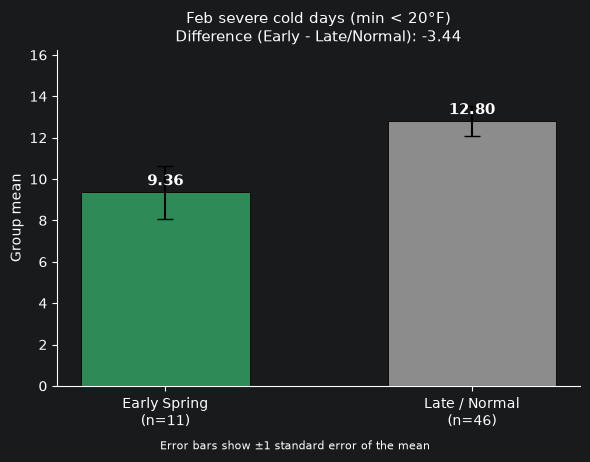

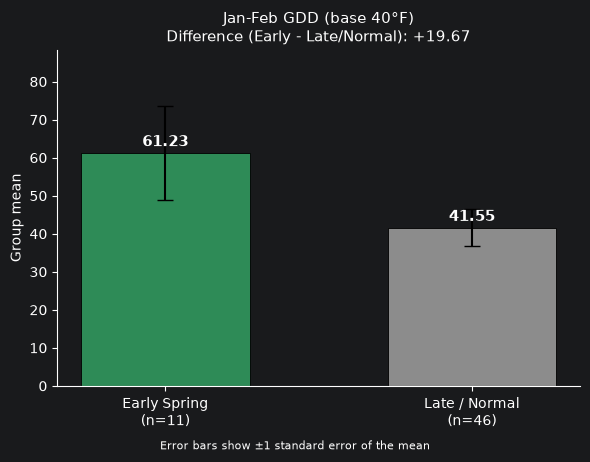

In [7]:
# Plotting the feature differences between Early Spring and Late/Normal years

GROUPS = ["Early Spring", "Late / Normal"]
COLORS = {"Early Spring": "#2e8b57", "Late / Normal": "#8c8c8c"}

grouped = yearly.groupby("group")[list(FEATURE_NAMES)]
means = grouped.mean().loc[GROUPS]
sems = grouped.sem().loc[GROUPS]
counts = yearly["group"].value_counts()


def plot_feature(col, label):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    bars = ax.bar(
        GROUPS,
        means[col],
        yerr=sems[col],
        capsize=6,
        color=[COLORS[g] for g in GROUPS],
        edgecolor="black",
        linewidth=0.6,
        width=0.55,
    )

    # Label each bar with its mean
    for bar, g in zip(bars, GROUPS):
        value = means.loc[g, col]
        offset = 5 if value >= 0 else -14
        ax.annotate(
            f"{value:.2f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            fontsize=11,
            fontweight="bold",
        )

    diff = means.loc["Early Spring", col] - means.loc["Late / Normal", col]
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{label}\nDifference (Early - Late/Normal): {diff:+.2f}", fontsize=11)
    ax.set_ylabel("Group mean")
    ax.set_xticks(range(len(GROUPS)))
    ax.set_xticklabels(
        [f"Early Spring\n(n={counts['Early Spring']})", f"Late / Normal\n(n={counts['Late / Normal']})"]
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.2)
    fig.text(0.5, -0.01, "Error bars show ±1 standard error of the mean", ha="center", fontsize=8)
    plt.tight_layout()
    plt.show()


for col, label in FEATURE_NAMES.items():
    plot_feature(col, label)

By separating the years into "Early Spring" and "Late / Normal" groups, we can observe the average values of the computed features for each group. The difference between the two groups is also calculated to highlight the features that may be indicative of early spring onset. The counts of each group are printed, along with the summary statistics for each feature, providing insights into how these features vary between early spring and late/normal years.

In particular, we can see that early spring years tend to have fewer snow cover days, higher late February air and soil temperatures, fewer severe cold days, and higher growing degree days (GDD) compared to late/normal years. These differences suggest that these features may be useful for predicting early spring onset.

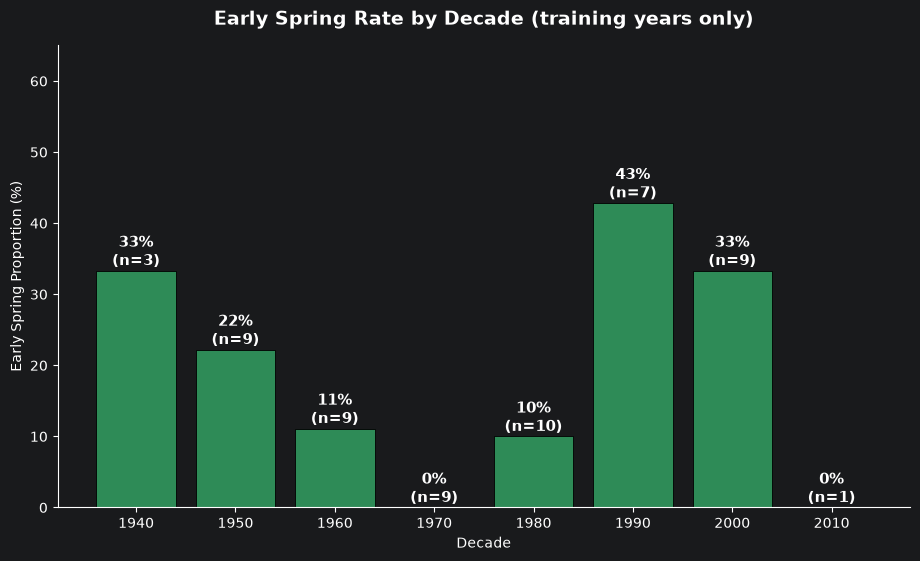

In [8]:
decade_stats = (
    train_set.assign(decade=train_set["year"] // 10 * 10)
    .groupby("decade")["early_spring"].agg(n_years="count", n_early="sum").reset_index()
)
decade_stats["rate"] = decade_stats["n_early"] / decade_stats["n_years"] * 100

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(decade_stats["decade"].astype(str), decade_stats["rate"],
              color="#2e8b57", edgecolor="black", linewidth=0.6)
for bar, (_, r) in zip(bars, decade_stats.iterrows()):
    ax.annotate(f"{r['rate']:.0f}%\n(n={int(r['n_years'])})",
                (bar.get_x() + bar.get_width() / 2, r["rate"]),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=11, fontweight="bold")
ax.set_title("Early Spring Rate by Decade (training years only)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Decade")
ax.set_ylabel("Early Spring Proportion (%)")
ax.set_ylim(0, 65)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In the training years the early-spring rate was low through the 1980s (0 of 9 labeled years in the 1970s, 1 of 10 in the 1980s) and rose to 43% in the 1990s and 33% in the 2000s. With only 7 to 10 labeled years per decade, each rate is noisy. The 2010 bar covers a single training year (2011 has no label and 2012 onward is held out for testing), so it should not be read as a drop. Interestingly, the 1970s decade was the only decade with no early-spring years in the training set, which may be a useful signal for the model to learn. The base rate shifts over time, which is why the test set is the most recent years, and why `year` needs a deliberate decision in the preparation step.

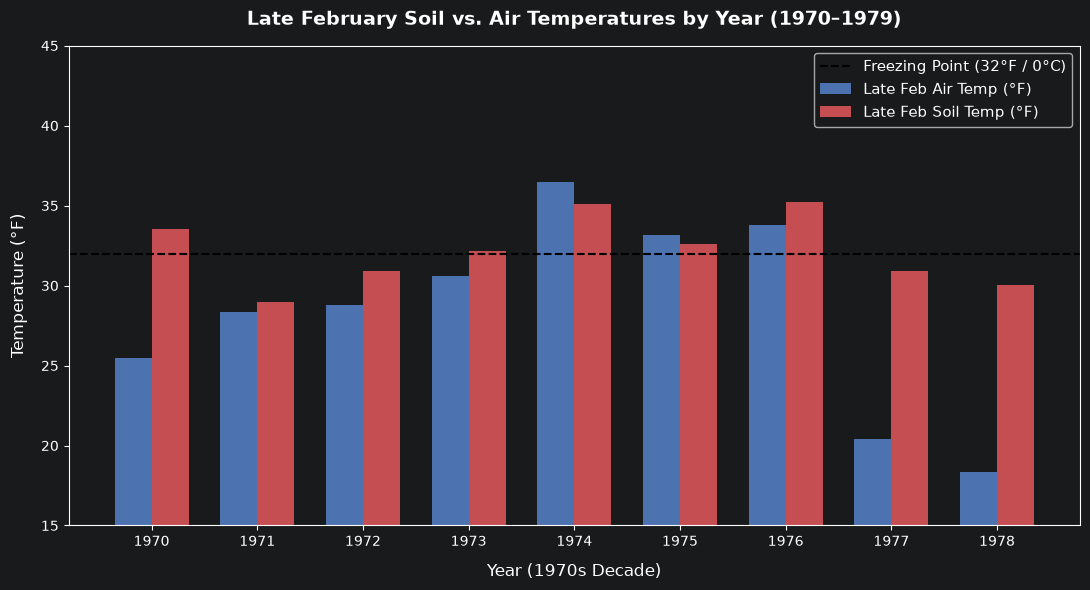

In [9]:
weather = pd.read_csv("weather.csv", parse_dates=["date"])

# Clean numerical weather columns (T = trace -> minimal snow, M = missing -> NaN)
numeric_cols = [
    "max_temp",
    "min_temp",
    "avg_temp",
    "precipitation",
    "snowfall",
    "snowdepth",
]
for col in numeric_cols:
  weather[col] = pd.to_numeric(
      weather[col].astype(str).str.strip().replace({"T": "0.01"}),
      errors="coerce",
  )

weather["avg_temp"] = weather["avg_temp"].fillna(
    (weather["max_temp"] + weather["min_temp"]) / 2
)

# Merge daily records prior to March 1 cutoff
daily = soil.merge(weather, on="date", how="outer").sort_values("date")
daily = daily[daily["date"].dt.month < 3].copy()
daily["year"] = daily["date"].dt.year
daily["mean_soil_temp_f"] = daily["mean_soil_temp"] * 1.8 + 32.0

# Filter 1970s decade late February observations (Last 15 days of Feb)
daily_1970s = daily[(daily["year"] >= 1970) & (daily["year"] <= 1979)]
feb_late_1970s = daily_1970s[daily_1970s["date"].dt.day >= 15]
yearly_1970s = (
    feb_late_1970s.groupby("year")[["avg_temp", "mean_soil_temp_f"]]
    .mean()
    .reset_index()
)


plt.figure(figsize=(11, 6))

x_years = yearly_1970s["year"]
width = 0.35

plt.bar(
    x_years - width / 2,
    yearly_1970s["avg_temp"],
    width,
    label="Late Feb Air Temp (°F)",
    color="#4c72b0",
)
plt.bar(
    x_years + width / 2,
    yearly_1970s["mean_soil_temp_f"],
    width,
    label="Late Feb Soil Temp (°F)",
    color="#c44e52",
)
plt.axhline(
    y=32,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Freezing Point (32°F / 0°C)",
)

plt.title(
    "Late February Soil vs. Air Temperatures by Year (1970–1979)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Year (1970s Decade)", fontsize=12, labelpad=10)
plt.ylabel("Temperature (°F)", fontsize=12, labelpad=10)
plt.xticks(x_years)
plt.ylim(15, 45)
plt.legend(loc="upper right", frameon=True, fontsize=11)

plt.tight_layout()
plt.show()

The bar chart shows that in some years, the air temperature was above freezing while the soil temperature remained below freezing, indicating that the ground had not yet thawed despite warmer air temperatures. This highlights the importance of considering both air and soil temperatures when assessing early spring onset, as soil temperature is a more direct indicator of ground thawing and plant growth potential.

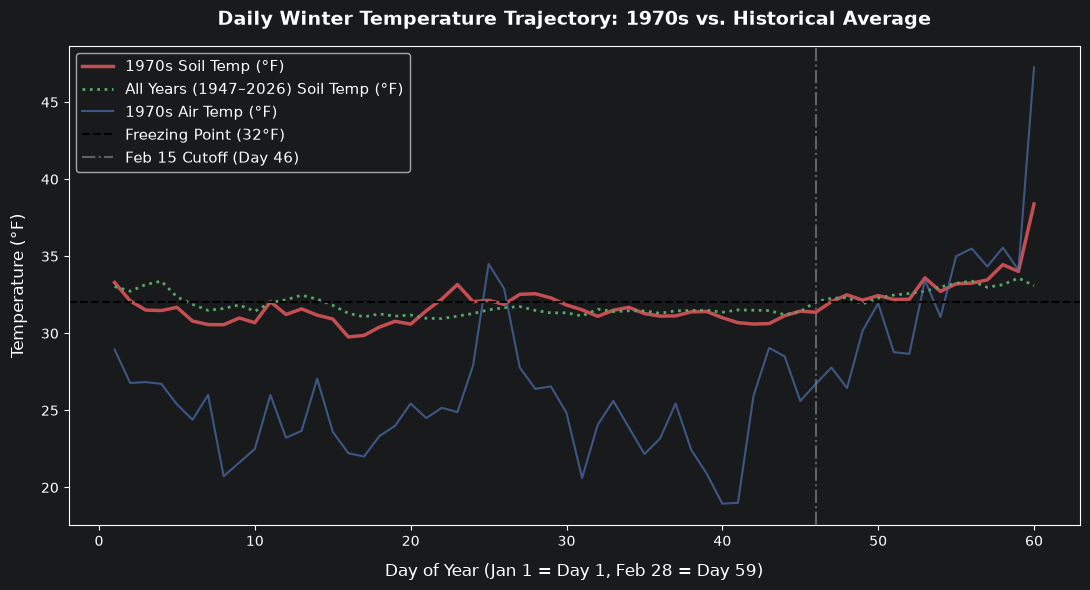

In [10]:
# Clean numerical weather columns (T = trace -> 0.01, M = missing -> NaN)
numeric_cols = [
    "max_temp",
    "min_temp",
    "avg_temp",
    "precipitation",
    "snowfall",
    "snowdepth",
]
for col in numeric_cols:
  weather[col] = pd.to_numeric(
      weather[col].astype(str).str.strip().replace({"T": "0.01"}),
      errors="coerce",
  )

weather["avg_temp"] = weather["avg_temp"].fillna(
    (weather["max_temp"] + weather["min_temp"]) / 2
)

# Merge daily records prior to March 1 cutoff
daily = soil.merge(weather, on="date", how="outer").sort_values("date")
daily = daily[daily["date"].dt.month < 3].copy()
daily["year"] = daily["date"].dt.year
daily["day_of_year"] = daily["date"].dt.day_of_year
daily["mean_soil_temp_f"] = daily["mean_soil_temp"] * 1.8 + 32.0

# Compute daily profile means (Jan 1 to Feb 28/29)
daily_1970s = daily[(daily["year"] >= 1970) & (daily["year"] <= 1979)]
daily_1970s_profile = (
    daily_1970s.groupby("day_of_year")[["avg_temp", "mean_soil_temp_f"]]
    .mean()
    .reset_index()
)
daily_all_profile = (
    daily.groupby("day_of_year")[["avg_temp", "mean_soil_temp_f"]]
    .mean()
    .reset_index()
)

plt.figure(figsize=(11, 6))

plt.plot(
    daily_1970s_profile["day_of_year"],
    daily_1970s_profile["mean_soil_temp_f"],
    label="1970s Soil Temp (°F)",
    color="#c44e52",
    linewidth=2.5,
)
plt.plot(
    daily_all_profile["day_of_year"],
    daily_all_profile["mean_soil_temp_f"],
    label="All Years (1947–2026) Soil Temp (°F)",
    color="#55a868",
    linestyle=":",
    linewidth=2.0,
)
plt.plot(
    daily_1970s_profile["day_of_year"],
    daily_1970s_profile["avg_temp"],
    label="1970s Air Temp (°F)",
    color="#4c72b0",
    linewidth=1.5,
    alpha=0.7,
)
plt.axhline(
    y=32,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Freezing Point (32°F)",
)
plt.axvline(
    x=46,
    color="gray",
    linestyle="-.",
    alpha=0.7,
    label="Feb 15 Cutoff (Day 46)",
)

plt.title(
    "Daily Winter Temperature Trajectory: 1970s vs. Historical Average",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel(
    "Day of Year (Jan 1 = Day 1, Feb 28 = Day 59)", fontsize=12, labelpad=10
)
plt.ylabel("Temperature (°F)", fontsize=12, labelpad=10)
plt.legend(loc="upper left", frameon=True, fontsize=11)

plt.tight_layout()
plt.show()

Seeing the daily temperature trajectories for the 1970s compared to the historical average provides insight into how the winter temperatures varied during that decade. The soil temperature remains below freezing for a longer period in the 1970s, while the air temperature shows more fluctuation. This reinforces the idea that soil temperature is a critical factor in determining early spring onset, as it directly affects the thawing of the ground and subsequent plant growth. Soil will have to be an important factor when determining the onset of early spring, as it is a more direct indicator of the conditions necessary for plant growth and development, while air temperature will assist in that, but not determine it on its own.

In [11]:
phil_eval = pd.DataFrame({"actual": y_train, "phil": train_set["phil_early"].astype(bool)})
print(f"Phil accuracy: {(phil_eval['actual'] == phil_eval['phil']).mean():.1%}  (n={len(phil_eval)})")
print(f"'Never early' baseline accuracy: {1 - y_train.mean():.1%}\n")
print(pd.crosstab(phil_eval["actual"], phil_eval["phil"],
                  rownames=["Actual early"], colnames=["Phil says early"]))

Phil accuracy: 68.4%  (n=57)
'Never early' baseline accuracy: 80.7%

Phil says early  False  True 
Actual early                 
False               38      8
True                10      1


The accuracy of Phil's predictions is calculated by comparing his predictions to the actual early spring labels. The overall accuracy is printed, along with the baseline accuracy of always predicting "never early." Additionally, a confusion matrix is displayed to show the counts of true positives, false positives, true negatives, and false negatives for Phil's predictions. This provides insight into how well Phil's predictions align with the actual early spring occurrences and highlights any potential biases or inaccuracies in his forecasting.

snow_days            -0.400
air_feb               0.400
snow_days_late       -0.314
cold_days            -0.310
soil_moisture         0.286
soil_feb              0.241
gdd                   0.223
air_feb_late          0.209
soil_feb_late         0.208
ao_nov               -0.184
oni_ndj              -0.166
oni_ond              -0.164
soil_trend            0.159
oni_son              -0.144
year                  0.099
phil_early           -0.090
ao_jan                0.072
soil_moisture_late    0.071
oni_trend            -0.066
ao_dec               -0.050
ao_winter_mean       -0.041


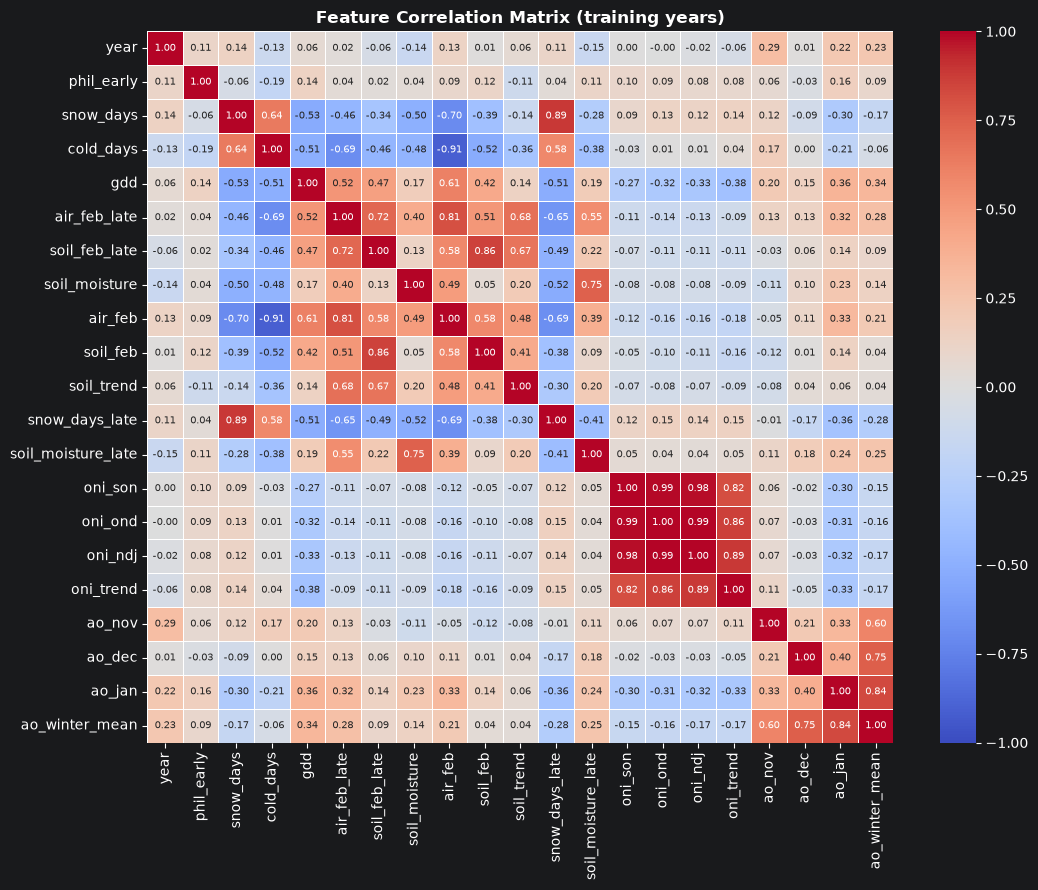

In [12]:
corr_target = (
    X_train.assign(early_spring=y_train.astype(int)).corr()["early_spring"]
    .drop("early_spring").sort_values(key=abs, ascending=False)
)
print(corr_target.round(3).to_string())

plt.figure(figsize=(11, 9))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.4, annot_kws={"size": 7})
plt.title("Feature Correlation Matrix (training years)", fontweight="bold")
plt.tight_layout()
plt.show()

When creating the correlation matrix, we created several additional features to better help us narrow down the most important features for predicting an early spring. This includes:
- `snow_days`: The number of days in February with snow cover (snowdepth > 0).
- `cold_days`: The number of days in February with minimum temperature below 20°F.
- `gdd`: The cumulative growing degree days (GDD) for January and February, calculated as the sum of (avg_temp - 40°F) for each day, with a minimum of 0.
- `air_feb_late`: The mean air temperature for the late February period (Last 15 days of February, accounting for leap years).
- `soil_feb_late`: The mean soil temperature for the late February period (Last 15 days of February, accounting for leap years).
- `soil_moisture`: The mean soil moisture for February.

When initially looking at the matrix, it's hard to find any strong correlations between features and the target variable `early_spring`. However, like previously mentioned, the combination of features may provide more insight into the prediction of early spring onset. For example, while `air_feb_late` and `soil_feb_late` may not show strong individual correlations with `early_spring`, they show strong correlations with each other, and their combined effect along with other features like `snow_days` and `cold_days` could be significant in determining the likelihood of an early spring.

In addition, all the ONI and AO features are included in the correlation matrix, but they do not show strong correlations with the target variable. However, they may still provide valuable information when combined with other features in a predictive model. Overall, the correlation matrix provides a useful overview of the relationships between features and the target variable, helping to guide feature selection and model development.

In [13]:
INDEX_COLS = ["oni_ndj", "ao_winter_mean"]   # Nov-Jan window only
index_df = train_set[["year", "early_spring"] + INDEX_COLS].copy()
index_df["early_spring"] = index_df["early_spring"].astype(int)
index_df["group"] = np.where(index_df["early_spring"] == 1, "Early Spring", "Late / Normal")
print(f"Years: {len(index_df)}  |  Early: {index_df['early_spring'].sum()}  |  Late/Normal: {(1 - index_df['early_spring']).sum()}\n")
index_df.info()

Years: 57  |  Early: 11  |  Late/Normal: 46

<class 'pandas.DataFrame'>
RangeIndex: 57 entries, 0 to 56
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            57 non-null     int64  
 1   early_spring    57 non-null     int64  
 2   oni_ndj         53 non-null     float64
 3   ao_winter_mean  53 non-null     float64
 4   group           57 non-null     str    
dtypes: float64(2), int64(2), str(1)
memory usage: 3.1 KB


The `index_df` DataFrame contains the years, early spring labels, and the selected index features (`oni_ndj` and `ao_winter_mean`). The early spring labels are converted to integers for easier analysis. A new column, `group`, is created to categorize the years into "Early Spring" and "Late / Normal" based on the early spring label. The number of years, early spring occurrences, and late/normal occurrences are printed, along with the DataFrame's information, including the number of entries, column names, data types, and memory usage. This provides a clear overview of the dataset and its structure for further analysis.

In [14]:
# Look at the features: how many are missing, and what do they look like?
print("Missing values per column (only those with some):")
missing = X_train.isna().sum()
print(missing[missing > 0])

X_train.describe().T.round(2)

Missing values per column (only those with some):
cold_days         1
air_feb_late      1
air_feb           1
oni_son           4
oni_ond           4
oni_ndj           4
oni_trend         4
ao_nov            4
ao_dec            4
ao_jan            3
ao_winter_mean    4
dtype: int64


,count,mean,std,min,25%,50%,75%,max
year,57.0,1977.86,18.75,1947.00,1962.00,1977.00,1994.00,2010.00
phil_early,57.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00
snow_days,57.0,19.37,7.30,5.00,14.00,21.00,26.00,29.00
cold_days,56.0,12.36,4.82,2.00,9.00,11.00,16.00,25.00
gdd,57.0,45.35,35.19,0.50,22.00,37.00,62.50,138.00
air_feb_late,56.0,31.99,6.11,15.57,28.31,31.53,36.72,44.30
soil_feb_late,57.0,0.22,1.34,-3.95,-0.54,-0.07,0.73,4.38
soil_moisture,57.0,0.47,0.01,0.45,0.47,0.47,0.48,0.49
air_feb,56.0,29.81,4.57,17.07,27.54,29.46,33.05,38.38
soil_feb,57.0,-0.09,1.03,-2.89,-0.78,-0.00,0.46,2.36


Although there are some missing values in the training set, they are relatively few and can be worked around. The `describe()` method provides summary statistics for each feature, including count, mean, standard deviation, minimum, maximum, and quartiles. This information helps us understand the distribution of the features and identify any potential outliers or anomalies that may affect the model's performance.

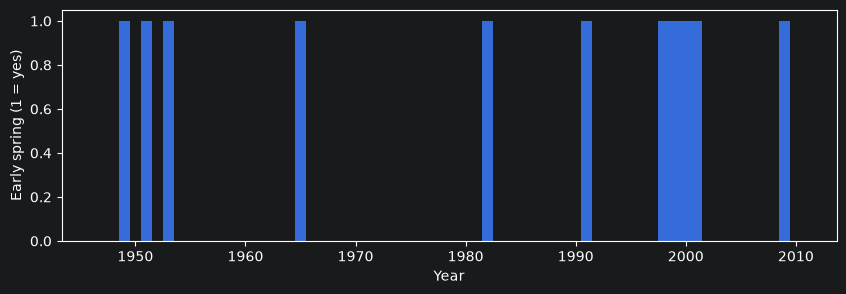

year
1940    0.33
1950    0.22
1960    0.11
1970    0.00
1980    0.10
1990    0.43
2000    0.33
2010    0.00
Name: early_spring, dtype: float64

In [15]:
# Look at the labels over time: the early spring rate has been climbing
plt.figure(figsize=(10, 3))
plt.bar(train_set.year, y_train, width=1.0)
plt.xlabel("Year")
plt.ylabel("Early spring (1 = yes)")
plt.show()

# Early spring rate by decade
y_train.groupby(train_set.year // 10 * 10).mean().round(2)

The early spring rate has been increasing over the years, which may indicate a trend related to climate change or other environmental factors. The bar chart shows the distribution of early spring occurrences over time, while the grouped mean by decade provides a clearer view of how the rate has changed across different periods. This information is essential for understanding the context of the data and for building predictive models that account for temporal trends.

In [16]:
SEED_COST = 0.2   # fraction of the extra harvest's revenue (client)

def profit_per_year(y_true, buy):
    # Average profit per year if we buy seeds whenever buy == True
    y_true, buy = np.asarray(y_true, dtype=bool), np.asarray(buy, dtype=bool)
    return np.mean(buy * (y_true * (1 - SEED_COST) - ~y_true * SEED_COST))

Seeds cost 20% of the extra harvest's revenue. A correct purchase gains 0.8, a wasted purchase loses 0.2, and not buying is 0. So we make money whenever more than 1 in 5 purchases pays off. Accuracy ignores this, so we also compute the profit per year of every set of predictions.

In [17]:
# The naive strategies to beat: never buy and always buy
print("Never buy: ", profit_per_year(y_train, np.zeros(len(y_train))))
print("Always buy:", profit_per_year(y_train, np.ones(len(y_train))))

Never buy:  0.0
Always buy: -0.0070175438596491125


In the training years **both simple strategies roughly break even**: *never buy* earns exactly 0, and *always buy* loses only a tiny amount (−0.007 R per year), because early springs (19%) were just below the 20% break-even. Following Phil is slightly worse. So a model is only useful if it can tell the good years from the bad ones: buy when there is a real chance of an early spring, skip the clearly bad winters.

| | Said buy | Said don’t buy |
| :--- | :--- | :--- |
| **Early spring happened** | **True Positive (TP):** bought, and it paid off | **False Negative (FN):** didn’t buy, missed the extra harvest |
| **Early spring didn’t happen** | **False Positive (FP):** bought, seeds wasted | **True Negative (TN):** didn’t buy, correctly saved the money |

* **Accuracy** = (TP + TN) / all years. It is misleading here: only about 19% of the training years are early springs, so *never buying* is already right about 81% of the time.
* **Precision** = TP / (TP + FP): of the years we bought, how many paid off. Because a win gains 0.8 and a loss costs 0.2, buying is profitable on average only when precision is **above 20%**.
* **Recall** = TP / (TP + FN): of the early springs, how many we caught.
* **Profit per year** combines them using the client’s costs, and is what we ultimately care about.

In [18]:
# Read the raw files as text so we can see the M and T codes
raw_weather = pd.read_csv("weather.csv", dtype=str)
raw_soil = pd.read_csv("soil.csv", parse_dates=["day"])
raw_weather["date"] = pd.to_datetime(raw_weather["date"])

weather_cols = ["max_temp", "min_temp", "avg_temp", "precipitation", "snowfall", "snowdepth"]
codes = raw_weather[weather_cols].apply(lambda s: s.str.strip())

# 1. Coding noise: how many M (missing) and T (trace) codes per column
audit = pd.DataFrame({
    "M (missing)": (codes == "M").sum(),
    "T (trace)":   (codes == "T").sum(),
})
audit["% missing"] = (audit["M (missing)"] / len(codes) * 100).round(1)
audit["% trace"]   = (audit["T (trace)"] / len(codes) * 100).round(1)
display(audit)

# 2. Rounding noise: how many readings are whole numbers?
w = codes.apply(pd.to_numeric, errors="coerce")
print("Share of readings that are whole numbers (rounding):")
print(((w % 1 == 0).sum() / w.notna().sum()).round(2).to_string())

# 3. Is avg_temp just the min/max midpoint?
mid = (w["max_temp"] + w["min_temp"]) / 2
print(f"\navg_temp equals the min/max midpoint (within 0.5 F): {np.isclose(w['avg_temp'], mid, atol=0.5)[w['avg_temp'].notna()].mean():.0%} of days")

# 4. Impossible or suspicious values
soil = raw_soil.assign(year=raw_soil["day"].dt.year)
checks = {
    "weather: max_temp < min_temp":            int((w["max_temp"] < w["min_temp"]).sum()),
    "weather: avg_temp outside [min, max]":    int(((w["avg_temp"] < w["min_temp"]) | (w["avg_temp"] > w["max_temp"])).sum()),
    "weather: negative precip / snow":         int((w[["precipitation", "snowfall", "snowdepth"]] < 0).sum().sum()),
    "weather: snowfall > 0 but snowdepth = 0": int(((w["snowfall"] > 0) & (w["snowdepth"] == 0)).sum()),
    "soil: min_soil_temp > max_soil_temp":     int((soil["min_soil_temp"] > soil["max_soil_temp"]).sum()),
    "soil: moisture outside 0-1":              int(((soil["mean_soil_moisture"] < 0) | (soil["mean_soil_moisture"] > 1)).sum()),
}
print("\nImpossible or suspicious values:")
print(pd.Series(checks).to_string())

# 5. Sensor noise: big day-to-day jumps in soil temperature (within the same year)
step = soil.sort_values("day").groupby("year")["mean_soil_temp"].diff().abs()
print(f"\nSoil temp day-to-day jumps over 3 C: {(step > 3).sum()} (largest {step.max():.1f} C)")

# 6. Stuck sensor: the longest run of identical soil moisture values in a year
def longest_run(s):
    runs = (s != s.shift()).cumsum()
    return s.groupby(runs).transform("size").max()
print("Longest run of identical daily soil moisture values:")
print(soil.groupby("year")["mean_soil_moisture"].apply(longest_run).sort_values().tail(3).to_string())

# 7. Systematic drift: does yearly soil moisture just creep up or down with time?
from scipy import stats
yearly_moisture = soil.groupby("year")["mean_soil_moisture"].mean()
rho, p = stats.spearmanr(yearly_moisture.index, yearly_moisture.values)
print(f"\nYearly mean soil moisture vs year: Spearman rho = {rho:.2f} (p = {p:.3f})")

,M (missing),T (trace),% missing,% trace
max_temp,89,0,2.1,0.0
min_temp,83,0,1.9,0.0
avg_temp,104,0,2.4,0.0
precipitation,16,692,0.4,16.0
snowfall,44,711,1.0,16.4
snowdepth,75,770,1.7,17.8


Share of readings that are whole numbers (rounding):
max_temp         1.00
min_temp         1.00
avg_temp         0.51
precipitation    0.41
snowfall         0.79
snowdepth        1.00

avg_temp equals the min/max midpoint (within 0.5 F): 100% of days

Impossible or suspicious values:
weather: max_temp < min_temp                0
weather: avg_temp outside [min, max]        0
weather: negative precip / snow             0
weather: snowfall > 0 but snowdepth = 0    16
soil: min_soil_temp > max_soil_temp         0
soil: moisture outside 0-1                  0

Soil temp day-to-day jumps over 3 C: 241 (largest 9.7 C)
Longest run of identical daily soil moisture values:
year
2001    7
1977    7
1980    8

Yearly mean soil moisture vs year: Spearman rho = 0.06 (p = 0.634)


Analyzing the noisiness in the weather and soil data reveals several important insights:
1. **Coding Noise**: The presence of "M" (missing) and "T" (trace) codes indicates that some data points are not available or are below measurable thresholds. This can affect the accuracy of the features derived from these columns.
2. **Sensor Noise**: The data shows instances of large day-to-day jumps in soil temperature, which may indicate sensor malfunctions or environmental factors.
3. **Rounding Noise**: A significant portion of the readings are whole numbers, which may indicate rounding in the data collection process. This can introduce bias or reduce the precision of the measurements.
4. **Outliers and Impossible Values**: There are no instances of impossible or suspicious values, such as negative precipitation or snow depth, and cases where the maximum temperature is less than the minimum temperature.

,n_unique,% zeros,skew,kurtosis,normal_p,shape
air_feb,56,0.0,-0.43,0.22,0.38,roughly normal
snow_days,23,0.0,-0.40,-1.09,0.00,not normal
ao_dec,53,0.0,-0.39,-0.64,0.08,roughly normal
ao_nov,53,0.0,-0.32,-0.44,0.12,roughly normal
snow_days_late,16,4.0,-0.30,-1.05,0.00,not normal
soil_moisture_late,57,0.0,-0.29,0.27,0.84,roughly normal
soil_moisture,57,0.0,-0.21,-0.21,0.77,roughly normal
ao_jan,54,0.0,-0.20,-0.09,0.58,roughly normal
air_feb_late,56,0.0,-0.18,-0.03,0.71,roughly normal
soil_feb,57,0.0,-0.12,0.96,0.21,roughly normal


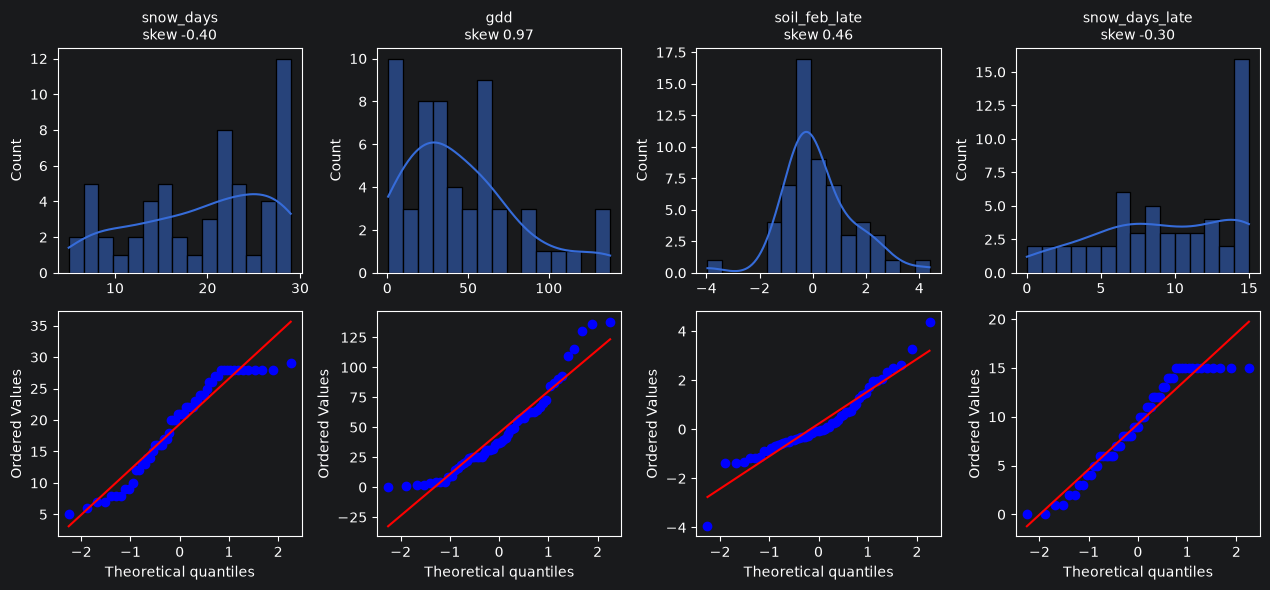

In [19]:
# Shape of each yearly feature (training years only)
feature_cols = [c for c in X_train.columns if c not in ("year", "phil_early")]
dist = pd.DataFrame({
    "n_unique": X_train[feature_cols].nunique(),
    "% zeros":  ((X_train[feature_cols] == 0).mean() * 100).round(0),
    "skew":     X_train[feature_cols].skew(),
    "kurtosis": X_train[feature_cols].kurt(),
    "normal_p": {c: stats.shapiro(X_train[c].dropna()).pvalue for c in feature_cols},
}).round(2)
dist["shape"] = np.select(
    [dist["% zeros"] > 10, dist["skew"].abs() > 1, dist["normal_p"] < 0.05],
    ["zero-inflated", "skewed", "not normal"], default="roughly normal")
display(dist.sort_values("skew"))

# Histogram (top) and QQ plot (bottom) for every feature that is not roughly normal
flagged = dist.index[dist["shape"] != "roughly normal"]
fig, axes = plt.subplots(2, len(flagged), figsize=(3.2 * len(flagged), 6), squeeze=False)
for i, c in enumerate(flagged):
    x = X_train[c].dropna()
    sns.histplot(x, kde=True, bins=15, ax=axes[0, i])
    axes[0, i].set_title(f"{c}\nskew {x.skew():.2f}", fontsize=10)
    axes[0, i].set_xlabel("")
    stats.probplot(x, dist="norm", plot=axes[1, i])
    axes[1, i].set_title("")
plt.tight_layout()
plt.show()

The distribution analysis of the yearly features in the training set reveals that several features exhibit skewed distributions, zero-inflation, or deviations from normality.  Features that are flagged as not roughly normal are visualized with histograms and QQ plots to assess their distributional characteristics. Specifically, `soil_feb_late`, `gdd`, and `snow_days` are skewed, while `snow_days_late` is zero-inflated. These characteristics can affect the performance of certain machine learning models, particularly those that assume normally distributed input features.

## How would we solve this manually?

Without a model, a farmer would look at how the winter has gone at the end of February and ask one question: **is there a better than 1-in-5 chance that spring will be early?** Seeds only need to pay off 1 time in 5 to break even (a win gains 0.8, a waste costs 0.2), so the bar for buying is low. The decision is really "is this winter clearly bad?", not "will spring definitely be early?"

**What the farmer would check, and what we have for it**

| What the farmer looks at | Feature we have | What points to an early spring | Correlation with early spring (training years) |
|---|---|---|---|
| How cold February was overall | `air_feb`, `cold_days` | Warmer average, fewer days below 20°F | +0.40, −0.31 |
| Is snow still on the ground? | `snow_days`, `snow_days_late` | Fewer days with snow cover (a trace counts as snow) | −0.40, −0.31 |
| Is the ground wet and thawing? | `soil_moisture`, `soil_feb`, `soil_feb_late` | Higher moisture, soil near or above 0°C | +0.29, +0.24, +0.21 |
| Has the winter been warm overall? | `gdd` | More growing degree days | +0.22 |
| Is the long-term pattern mild? | `oni_ndj`, `ao_winter_mean` | El Niño, positive AO | −0.17, −0.04 |
| Is early spring common lately? | `year` | Recent years | +0.10 |
| What did the groundhog say? | `phil_early` | Phil sees no shadow | −0.09 |

**A rule of thumb a farmer could follow**

1. Start from "buy". Early springs only need to come 1 year in 5.
2. Don't buy if February was clearly cold and snowy: many cold days, many snow-cover days, and a below-average February air temperature.
3. Buy if February was mild: few snow days, few cold days, and above-average air temperature.
4. For the unclear years in between, lean toward buying, because a wasted purchase costs 0.2 while a missed early spring costs 0.8.
5. Ignore Phil. He is right on only 1 of the 9 years he calls early, below the 20% needed to break even.

**Why a model can still help**

* A farmer weighs a few signals by feel. A model can combine all of them at once and give a probability, not just buy / don't buy.
* No single feature separates the years well (the strongest correlation is only about 0.40), so the signal is spread across several weak ones.
* The model can use the break-even threshold of 20% directly, and gets scored on profit per year.
* This manual rule becomes one of the baselines the model has to beat, along with never buy, always buy and Phil.

## Promising transformations

| Transformation | Applies to | Why | What to check first |
|---|---|---|---|
| **Trace (`T`) → a very small positive value** (e.g. 0.01 in) | `snowdepth` (optionally `snowfall`, `precipitation`) | A trace is a measurable amount of snow, so `0` erases it. With a small positive value, a day with trace snow counts as a snow day in `snow_days` | % of trace readings (audit cell below), and whether `snow_days` correlates better with the label |
| **Keep missing (`M`) as `NaN`**, never 0 | all weather columns | A missing reading is not "no snow". We also add a missing-value flag in Preparation | % missing per column |
| **Recompute `avg_temp` as the min/max midpoint** | `avg_temp` | If the audit shows the station already defines it this way, this is its own rule, not a guess | Midpoint check in the audit |
| **Counts as a share of days** (÷ 28 or 29) | `snow_days`, `cold_days`, `snow_days_late` | February has 28 or 29 days; `gdd` sums 59 or 60 days. A leap year gets one extra day to accumulate | Small effect, but free |
| **Skew-fixing: sqrt, log1p** | only features flagged as skewed or zero-inflated | Helps linear models, SVM and KNN. It over-corrects near-symmetric features, so apply selectively | Distribution table and before/after skew |
| **Common units** | any feature mixing air and soil | Air is in °F and soil in °C; convert one before subtracting or combining | Units in the data tables |
| **Anomalies vs. recent winters** | temperatures, snow, soil | Feature minus the mean of the previous ~10 winters (past years only) removes the warming trend | Drift of each feature with year |
| **Soil thaw timing** | daily soil temperature | Soil hovers near 0°C all winter, so averages hide it. Days above 0°C, first day above 0°C, and freeze-thaw crossings may separate the groups better | Boxplot by label |
| **Scaling** | all | Robust or power scaling for skewed features, standard scaling for the rest | Distribution table |

## Extra data that would be useful

Data we don't have that could make the predictions better, roughly from most to least useful:

| Data | Why it would help | Can we get it? |
|---|---|---|
| **NOAA's late-February outlook for March–April** (Climate Prediction Center) | Spring is decided in late March and April, after our data stops. This is a real forecast of exactly that period, published before the March 1 deadline | Yes, public and free, but only archived for recent decades |
| **Weather from a nearby NOAA station** (GHCN-Daily) | Could fill the farm's gaps (no air temperatures for January 2001 and February 2004) and double-check the farm's sensors | Yes, public; we would need the farm's approximate location |
| **Deeper soil temperatures** (4–8 inches) | The 3-inch soil sits near 0 °C all February, so it barely changes between years. Deeper soil holds heat longer and may say more about spring | Only if the farm's sensors measure it |
| **Early March weather** | Would likely improve predictions a lot | No: the client confirmed seeds must be ordered by March 1 |
| **More years of labeled data** | 57 training years with only 11 early springs is the biggest limit on every model | No: the farm's records start in 1947 |
| **Records from the other farms in the consortium** | More years and more locations to learn from | Maybe; worth asking the client |

## What we learned

1. **The data is small and unbalanced.** Only 57 training years, and just 11 of them (19%) were early springs. Every pattern we find is uncertain, so we trust features that are both visible in the data *and* make physical sense.
2. **Early springs are becoming more common.** None in the 1970s, about 1 in 3 or more in the 1990s–2000s, and about half of the most recent years. This is why the test set is the most recent 15 years, and why `year` may matter.
3. **Snow and February cold are the strongest signals.** Fewer snow-cover days, less snowfall, a warmer February and fewer very cold nights all go with early springs (correlations around 0.3–0.4). No single feature separates early and late springs on its own.
4. **Looking at individual days matters.** February averages hide single cold nights and short thaws. Counting days that pass a threshold (snow on the ground, nights below 20 °F) shows the differences more clearly.
5. **Trace snow should count as snow.** A `T` reading means a thin layer of snow, not bare ground. Treating it as a small positive amount makes the snow features more strongly related to early springs.
6. **Soil temperature is less useful in February than expected.** Even though soil is the client's most important planting condition, the top 3 inches stay near freezing all winter in almost every year, so February soil readings barely differ between early and late springs.
7. **Several features say the same thing.** For example, February air temperature and the number of cold days are almost perfectly related. Keeping all of them adds noise, so Preparation keeps one or two from each group.
8. **Combinations help.** Warm air only helps if there is no snow on the ground; a cold *and* snowy late February almost never led to an early spring.
9. **Phil and the climate indices are weak.** Phil was right on only 1 of his 9 early-spring calls, below the 20% needed to break even. El Niño and the Arctic Oscillation show little relationship to early springs in our data.
10. **The data is clean.** No impossible values, few missing values (climate indices before 1950, and January 2001 and February 2004 air temperatures), and no sign of sensor drift.